# Fase 3: Entrenamiento y versionado de modelos

El entrenamiento completo se corre con:

```
python src/train_model.py
```

Ese script prueba los modelos, anota cada prueba en `results/experiment_logs.csv`, elige el mejor, lo guarda en `models/` con su número de versión y lo registra en `models/model_registry.json`.

En este notebook **no volvemos a elegir nada**: leemos lo que generó el script y lo analizamos. Usamos las mismas funciones del script para no repetir código.

El notebook muestra la versión actual del modelo, la **1.1.0**. Al final la comparamos con la 1.0.0.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path("..") / "src"))
import train_model as tm
from preprocessing_pipeline import VARIABLES, OBJETIVO, SEMILLA

partes = tm.cargar_datos()
train, validation, test = partes["train"], partes["validation"], partes["test"]

pd.DataFrame({
    "filas": [len(train), len(validation), len(test)],
    "desde": [p.index.min().date() for p in (train, validation, test)],
    "hasta": [p.index.max().date() for p in (train, validation, test)],
}, index=["train", "validation", "test"])

,filas,desde,hasta
train,843,2020-07-01,2022-10-21
validation,180,2022-10-22,2023-04-23
test,182,2023-04-24,2023-10-24


Para elegir modelo e hiperparámetros usamos **solo validation**. Test se usa una única vez, al final, con el modelo ya elegido. Elegir mirando test sería fuga de datos: el número final dejaría de representar datos que el modelo no vio.

## 1. Baselines

Antes de entrenar nada, dos predicciones que no necesitan modelo. Son la vara contra la que medimos todo lo demás:

- **Persistencia:** mañana se consume lo mismo que hoy.
- **Media móvil de 7 días:** mañana se consume el promedio de los últimos 7 días.

In [2]:
baselines_validation = pd.DataFrame(tm.baselines(validation)).T
baselines_validation

,MAE,RMSE,R2
Persistencia,2863.74,3589.62,0.1804
Media móvil 7 días,2583.01,3411.63,0.2597


La media móvil es mejor que la persistencia: promediar una semana saca el ruido de un día puntual. Un modelo que no baje de ese MAE no sirve para nada.

## 2. Modelos y espacio de búsqueda

Probamos cinco modelos: dos lineales con regularización (Ridge y Lasso) y tres de árboles (Random Forest, XGBoost y LightGBM).

Cada uno es un `Pipeline` de scikit-learn:

- Todos empiezan imputando con la mediana los pocos faltantes que quedan (los promedios móviles de los primeros días).
- Ridge y Lasso además estandarizan, porque la penalización depende de la escala de las variables. Los árboles no lo necesitan.

Al estar dentro del pipeline, la mediana, la media y el desvío se calculan solo con los datos con los que se entrena.

Este es el espacio de búsqueda. De cada modelo se prueban todas las combinaciones:

In [3]:
filas = []
for modelo, espacio in tm.ESPACIO_DE_BUSQUEDA.items():
    combinaciones = int(np.prod([len(valores) for valores in espacio.values()]))
    for hiperparametro, valores in espacio.items():
        filas.append({"modelo": modelo, "hiperparametro": hiperparametro, "valores": valores, "combinaciones_del_modelo": combinaciones})
pd.DataFrame(filas).set_index(["modelo", "combinaciones_del_modelo", "hiperparametro"])

valores
modelo       combinaciones_del_modelo hiperparametro                           
Ridge        5                        alpha             [0.1, 1, 10, 100, 1000]
Lasso        5                        alpha             [1, 10, 100, 500, 1000]
RandomForest 12                       n_estimators                        [300]
                                      max_depth                   [6, 10, None]
                                      min_samples_leaf           [3, 5, 10, 20]
XGBoost      12                       n_estimators                   [200, 400]
                                      learning_rate                [0.02, 0.05]
                                      max_depth                       [2, 3, 4]
LightGBM     12                       n_estimators                   [200, 400]
                                      learning_rate                [0.02, 0.05]
                                      num_leaves                     [4, 8, 15]

Qué controla cada hiperparámetro:

- **`alpha`** (Ridge y Lasso): la fuerza de la penalización. Más alto es un modelo más simple. En Lasso, además, lleva coeficientes a cero.
- **`max_depth`, `num_leaves`, `min_samples_leaf`**: el tamaño de los árboles. Árboles más chicos sobreajustan menos, y tenemos pocos datos (843 días de train).
- **`n_estimators` y `learning_rate`** (XGBoost y LightGBM): cuántos árboles se suman y cuánto corrige cada uno.

El espacio es chico a propósito: con tan pocos datos, probar cientos de combinaciones termina eligiendo la que tuvo suerte en validation.

## 3. Experimentos

Cada combinación se entrena con train, se evalúa en validation y queda en una fila de `results/experiment_logs.csv`, con sus hiperparámetros, las métricas y la fecha y hora. Si el script se corre varias veces, las corridas se van agregando. Acá miramos la última.

In [4]:
logs = pd.read_csv(tm.RUTA_LOGS)
ultima = logs[logs["corrida"] == logs["corrida"].max()]

print("Corridas en el archivo:", logs["corrida"].nunique(), "| Experimentos en la última:", len(ultima))
ultima.sort_values("MAE").head(10)[["timestamp", "modelo", "hiperparametros", "MAE", "RMSE", "R2", "MAE_train"]]

Corridas en el archivo: 2 | Experimentos en la última: 46


,timestamp,modelo,hiperparametros,MAE,RMSE,R2,MAE_train
54,2026-11-15T00:36:06,Lasso,"{""alpha"": 500}",2190.69,2916.91,0.4588,2958.68
53,2026-11-15T00:36:06,Lasso,"{""alpha"": 100}",2224.07,2967.34,0.4400,2905.09
50,2026-11-15T00:36:06,Ridge,"{""alpha"": 1000}",2245.78,3006.52,0.4251,3085.56
47,2026-11-15T00:36:06,Ridge,"{""alpha"": 1}",2261.85,2997.95,0.4283,2871.85
51,2026-11-15T00:36:06,Lasso,"{""alpha"": 1}",2262.59,2998.01,0.4283,2871.72
46,2026-11-15T00:36:06,Ridge,"{""alpha"": 0.1}",2262.73,2997.68,0.4285,2871.10
48,2026-11-15T00:36:06,Ridge,"{""alpha"": 10}",2266.20,3005.00,0.4257,2882.22
52,2026-11-15T00:36:06,Lasso,"{""alpha"": 10}",2267.53,3005.46,0.4255,2879.04
55,2026-11-15T00:36:06,Lasso,"{""alpha"": 1000}",2289.08,3014.47,0.4220,3068.33
49,2026-11-15T00:36:06,Ridge,"{""alpha"": 100}",2312.00,3058.07,0.4052,2952.25


In [5]:
# El mejor experimento de cada modelo
mejores = ultima.loc[ultima.groupby("modelo")["MAE"].idxmin()].sort_values("MAE").set_index("modelo")
mejores[["hiperparametros", "MAE", "RMSE", "R2", "MAE_train", "segundos_entrenamiento"]]

,hiperparametros,MAE,RMSE,R2,MAE_train,segundos_entrenamiento
modelo,,,,,,
Lasso,"{""alpha"": 500}",2190.69,2916.91,0.4588,2958.68,0.015
Ridge,"{""alpha"": 1000}",2245.78,3006.52,0.4251,3085.56,0.005
LightGBM,"{""n_estimators"": 200, ""learning_rate"": 0.02, ""...",2339.99,3044.89,0.4103,2204.74,0.207
XGBoost,"{""n_estimators"": 200, ""learning_rate"": 0.02, ""...",2352.38,3065.72,0.4022,2228.34,0.407
RandomForest,"{""n_estimators"": 300, ""max_depth"": 6, ""min_sam...",2379.33,3090.15,0.3926,2638.70,0.578


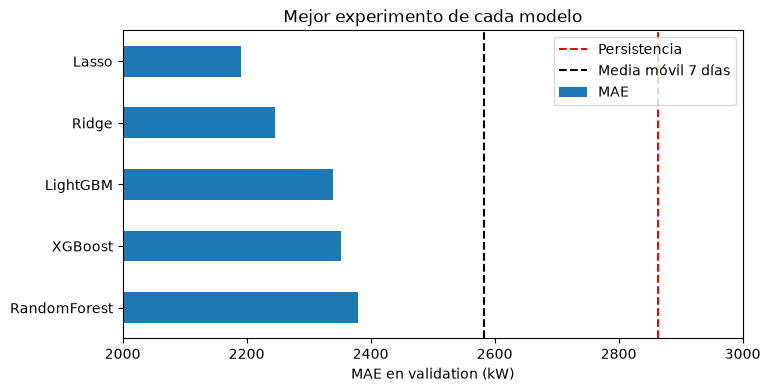

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
mejores["MAE"].sort_values(ascending=False).plot.barh(ax=ax)
ax.axvline(baselines_validation.loc["Persistencia", "MAE"], color="red", linestyle="--", label="Persistencia")
ax.axvline(baselines_validation.loc["Media móvil 7 días", "MAE"], color="black", linestyle="--", label="Media móvil 7 días")
ax.set_xlabel("MAE en validation (kW)")
ax.set_ylabel("")
ax.set_title("Mejor experimento de cada modelo")
ax.set_xlim(2000, 3000)
ax.legend()
plt.show()

Los cinco modelos le ganan a los dos baselines en validation. Entre el mejor (Lasso, 2.191 kW) y el peor (Random Forest, 2.379 kW) hay unos 190 kW.

Dos cosas para notar:

- **Los modelos lineales rinden mejor que los de árboles.** La relación entre el consumo de los últimos días y el de mañana es casi lineal (lo vimos en los gráficos de dispersión del EDA), y con 843 días de train los árboles no tienen datos suficientes para encontrar algo más complejo.
- **Los árboles sobreajustan más.** LightGBM tiene un MAE de 2.205 kW en train y de 2.340 kW en validation: aprendió detalles de train que después no se repiten. En Lasso pasa al revés (2.959 en train y 2.191 en validation), y no es porque sea mejor con datos nuevos: el período de train es más difícil. Ahí el consumo varía mucho más (desvío de unos 8.000 kW, contra 4.000 en validation) y hasta la persistencia se equivoca más (3.519 kW contra 2.864).

**Decisión: elegimos Lasso con `alpha = 500`**, porque es el de menor MAE en validation. Además es el más simple, el más rápido de entrenar y el más fácil de interpretar. El mejor `alpha` quedó en el medio de los valores probados (100, 500, 1000), así que el espacio de búsqueda alcanzó.

En Ridge el mejor `alpha` fue el más alto que probamos (1000), o sea que quizás mejoraba con más penalización. No ampliamos el espacio de búsqueda: lo dejamos igual que en la versión 1.0.0 para que lo único que cambie entre las dos versiones sean las variables.

## 4. Análisis de residuos

Volvemos a entrenar el modelo elegido con train (igual que en la búsqueda) y miramos sus errores en validation. El residuo es el valor real menos la predicción.

In [7]:
registro = json.load(open(tm.RUTA_REGISTRO, encoding="utf-8"))[tm.VERSION]
nombre_modelo, hiperparametros = registro["modelo"], registro["hiperparametros"]

modelo_en_train = tm.crear_modelo(nombre_modelo, hiperparametros).fit(train[VARIABLES], train[OBJETIVO])
prediccion = pd.Series(modelo_en_train.predict(validation[VARIABLES]), index=validation.index)
residuos = validation[OBJETIVO] - prediccion

print("Modelo:", nombre_modelo, hiperparametros)
print("Métricas en validation:", tm.metricas(validation[OBJETIVO], prediccion))
print("Residuo promedio:", round(residuos.mean(), 1), "kW | Residuo mediano:", round(residuos.median(), 1), "kW")

Modelo: Lasso {'alpha': 500}
Métricas en validation: {'MAE': 2190.69, 'RMSE': 2916.91, 'R2': 0.4588}
Residuo promedio: -206.2 kW | Residuo mediano: -354.3 kW


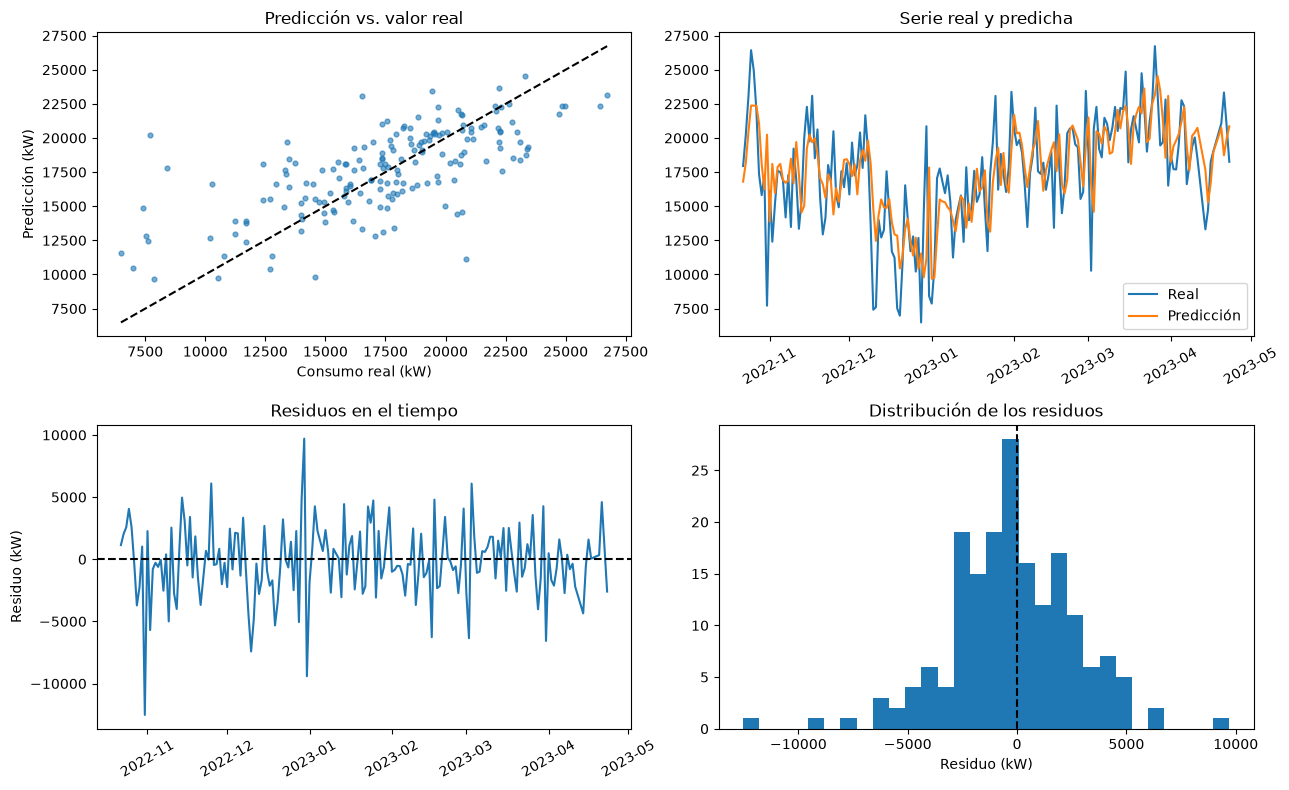

In [8]:
fig, ejes = plt.subplots(2, 2, figsize=(13, 8))

# Predicción contra valor real: si el modelo fuera perfecto, los puntos caerían sobre la diagonal
ax = ejes[0, 0]
ax.scatter(validation[OBJETIVO], prediccion, s=12, alpha=0.6)
limites = [validation[OBJETIVO].min(), validation[OBJETIVO].max()]
ax.plot(limites, limites, color="black", linestyle="--")
ax.set_xlabel("Consumo real (kW)")
ax.set_ylabel("Predicción (kW)")
ax.set_title("Predicción vs. valor real")

# Las dos series en el tiempo
ax = ejes[0, 1]
ax.plot(validation.index, validation[OBJETIVO], label="Real")
ax.plot(prediccion.index, prediccion, label="Predicción")
ax.set_title("Serie real y predicha")
ax.tick_params(axis="x", rotation=30)
ax.legend()

# Residuos en el tiempo: no tendría que haber tramos largos todos arriba o todos abajo
ax = ejes[1, 0]
ax.plot(residuos.index, residuos)
ax.axhline(0, color="black", linestyle="--")
ax.set_ylabel("Residuo (kW)")
ax.set_title("Residuos en el tiempo")
ax.tick_params(axis="x", rotation=30)

# Distribución de los residuos
ax = ejes[1, 1]
ax.hist(residuos, bins=30)
ax.axvline(0, color="black", linestyle="--")
ax.set_xlabel("Residuo (kW)")
ax.set_title("Distribución de los residuos")

plt.tight_layout()
plt.show()

In [9]:
# Los 5 días con mayor error, y el error según el día de la semana que se predice
print(residuos.abs().nlargest(5).round(0).to_string())
print()
nombres_dias = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
por_dia = residuos.abs().groupby(validation["dia_semana"]).mean().round(0)
por_dia.index = [nombres_dias[int(d)] for d in por_dia.index]
por_dia.to_frame("MAE (kW)").T

dia
2022-10-31    12526.0
2022-12-30     9703.0
2022-12-31     9412.0
2022-12-10     7419.0
2023-03-31     6573.0



,lunes,martes,miércoles,jueves,viernes,sábado,domingo
MAE (kW),1647.0,2392.0,2274.0,1969.0,2022.0,3071.0,1969.0


Lo que se ve:

- **El modelo sigue el nivel del consumo, pero suavizado.** En el gráfico de las series, la predicción acompaña las subas y bajadas de varios días y no llega a los picos ni a los pozos de un día puntual. Es esperable: una de sus variables principales es un promedio de dos semanas.
- **Los peores errores son caídas bruscas que no se pueden anticipar.** El mayor es el del 2022-10-31: predijo unos 20.200 kW para el día siguiente y se consumieron 7.714. Otros tres de los cinco peores son de diciembre. Son días en que la planta paró o bajó mucho la producción, y nada de lo que pasó el día anterior lo avisa.
- **Sobreestima un poco.** El residuo promedio es de -206 kW: en promedio predice de más. Validation es un período de consumo más bajo que train (unos 17.500 kW de promedio contra 25.000), y el modelo aprendió con consumos más altos.
- **No quedan tramos largos con el error siempre del mismo lado**, y el histograma está centrado cerca de cero, con una cola hacia la izquierda por las caídas bruscas.
- **Por día de la semana**, el error más alto es al predecir los sábados (unos 3.100 kW) y el más bajo los lunes (unos 1.650). Con unos 25 días de cada tipo en validation no alcanza para sacar una conclusión firme.

En el gráfico de dispersión los puntos forman una nube más acostada que la diagonal: a los días de consumo bajo les predice de más y a los de consumo alto de menos. Es el efecto de un modelo regularizado, que prefiere quedarse cerca del promedio antes que arriesgarse.

## 5. Importancia de variables

Usamos la importancia por permutación sobre validation: se desordena una variable por vez y se mide cuánto empeora el MAE. Si al desordenarla el error casi no cambia, el modelo no la está usando. Sirve para cualquier modelo y se mide con datos que el modelo no vio.

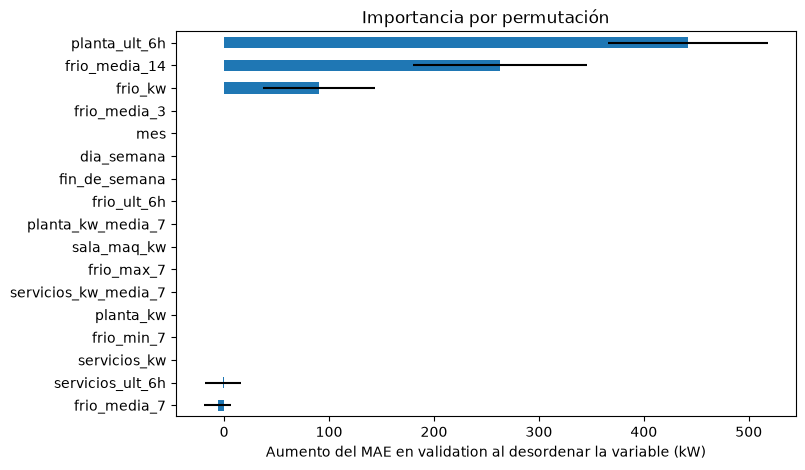

,aumento_del_MAE,desvio,coeficiente
planta_ult_6h,441.8,76.1,1509.4
frio_media_14,263.3,83.0,2989.6
frio_kw,90.2,53.6,1604.7
frio_min_7,0.0,0.0,0.0
frio_media_3,0.0,0.0,0.0
servicios_kw,0.0,0.0,0.0
sala_maq_kw,0.0,0.0,0.0
planta_kw,0.0,0.0,0.0
frio_max_7,0.0,0.0,0.0
dia_semana,0.0,0.0,-0.0


In [10]:
from sklearn.inspection import permutation_importance

permutacion = permutation_importance(
    modelo_en_train, validation[VARIABLES], validation[OBJETIVO],
    scoring="neg_mean_absolute_error", n_repeats=30, random_state=SEMILLA,
)
importancia = pd.DataFrame({
    "aumento_del_MAE": permutacion.importances_mean,
    "desvio": permutacion.importances_std,
}, index=VARIABLES).sort_values("aumento_del_MAE", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
importancia["aumento_del_MAE"].sort_values().plot.barh(ax=ax, xerr=importancia["desvio"].reindex(importancia["aumento_del_MAE"].sort_values().index))
ax.set_xlabel("Aumento del MAE en validation al desordenar la variable (kW)")
ax.set_title("Importancia por permutación")
plt.show()

# Si el modelo es lineal mostramos también sus coeficientes (sobre variables estandarizadas)
if hasattr(modelo_en_train[-1], "coef_"):
    importancia["coeficiente"] = pd.Series(modelo_en_train[-1].coef_, index=VARIABLES)
importancia.round(1)

El modelo se apoya sobre todo en **tres variables**:

- **`planta_ult_6h`**, el consumo de toda la planta en las últimas 6 horas del día. Es la más importante: desordenarla sube el MAE unos 440 kW. Dice cuánto estaba trabajando la planta al cerrar el día, que es la mejor pista de cómo va a arrancar el siguiente.
- **`frio_media_14`**, el promedio de frío de las últimas dos semanas (unos 260 kW). Marca en qué nivel de la temporada estamos.
- **`frio_kw`**, el consumo de frío de hoy (unos 90 kW).

`frio_media_7` y `servicios_ult_6h` tienen coeficientes chicos, y el resto quedó en cero. Es justamente lo que hace Lasso: quedarse con pocas variables y anular las redundantes. Por eso `sala_maq_kw` y `servicios_kw`, que son casi una copia de `frio_kw`, no aportan nada una vez que `frio_kw` está en el modelo.

Las variables de calendario (`dia_semana`, `mes`, `fin_de_semana`) también quedaron en cero. Coincide con el EDA, donde el día de la semana explicaba el 0,5% de la variación del consumo.

La interpretación: **el consumo de mañana se parece a un promedio entre el de hoy y el de las últimas dos semanas, corregido por cuánto estaba trabajando la planta al terminar el día**.

## 6. Modelo final y registro

El script reentrena el modelo elegido con **train + validation**, para aprovechar los datos más recientes, y lo guarda con versión semántica en `models/modelo_v1.1.0.pkl`. Recién ahí se evalúa en test.

Todo queda anotado en `models/model_registry.json`:

In [11]:
print("Versión:", registro["version"])
print("Archivo:", registro["path"])
print("Modelo:", registro["modelo"], registro["hiperparametros"])
print("Entrenado con:", registro["entrenado_con"], registro["filas"])
print("Commit de Git:", registro["commit_git"])
print("Fecha de entrenamiento:", registro["fecha_entrenamiento"])
print("Métricas en validation:", registro["metricas_validacion"])
print("MAE por fold (validación cruzada temporal):", registro["mae_validacion_cruzada"])

Versión: 1.1.0
Archivo: models/modelo_v1.1.0.pkl
Modelo: Lasso {'alpha': 500}
Entrenado con: train + validation {'train': 843, 'validation': 180, 'test': 182}
Commit de Git: fd07136bc451a67ac349cf6752ac6c551831a1ac
Fecha de entrenamiento: 2026-11-15T00:36:24
Métricas en validation: {'MAE': 2190.69, 'RMSE': 2916.91, 'R2': 0.4588}
MAE por fold (validación cruzada temporal): {'folds': [4675.16, 3821.23, 2863.89, 3115.29, 2134.21], 'media': 3321.96, 'desvio': 967.43}


In [12]:
# Los tres sobre el mismo conjunto de test y con el mismo preprocesamiento
tabla_test = pd.DataFrame({**registro["baselines_test"], "Modelo final": registro["metricas_test"]}).T
mejor_baseline = min(m["MAE"] for m in registro["baselines_test"].values())
tabla_test["mejora_sobre_mejor_baseline_%"] = ((mejor_baseline - tabla_test["MAE"]) / mejor_baseline * 100).round(1)
tabla_test

,MAE,RMSE,R2,mejora_sobre_mejor_baseline_%
Persistencia,3492.30,4724.73,0.3059,-13.9
Media móvil 7 días,3067.20,3966.97,0.5107,0.0
Modelo final,2708.79,3713.99,0.5711,11.7


Los tres números están medidos sobre el mismo conjunto de test, con el mismo preprocesamiento.

- **El modelo le gana a los dos baselines**: 2.709 kW contra 3.067 de la media móvil y 3.492 de la persistencia.
- **El MAE queda por debajo de 3.000 kW**, con unos 290 kW de margen.
- **La mejora sobre el mejor baseline es de 11,7%.**
- **El error cambia mucho de un período a otro.** En la validación cruzada temporal el MAE por fold va de 2.134 a 4.675 kW, con un desvío de 967 kW. El MAE de un período no garantiza el de otro.

En test el error es más alto que en validation (2.709 contra 2.191) porque es un período de más consumo y más variable. A los baselines les pasa lo mismo.

## 7. Comparación entre versiones

El registro guarda todas las versiones del modelo. `predict.py` usa siempre la más alta.

In [13]:
todas = json.load(open(tm.RUTA_REGISTRO, encoding="utf-8"))

pd.DataFrame({
    version: {
        "modelo": f"{entrada['modelo']} {entrada['hiperparametros']}",
        "n_variables": len(entrada["variables"]),
        "MAE_validation": entrada["metricas_validacion"]["MAE"],
        "MAE_test": entrada["metricas_test"]["MAE"],
        "mejora_sobre_mejor_baseline_%": entrada["mejora_sobre_mejor_baseline_test_pct"],
        "cambios": tm.CAMBIOS.get(version, ""),
    }
    for version, entrada in todas.items()
}).T

,modelo,n_variables,MAE_validation,MAE_test,mejora_sobre_mejor_baseline_%,cambios
1.0.0,Lasso {'alpha': 500},14,2294.04,2868.21,6.49,Primera versión: 14 variables calculadas con l...
1.1.0,Lasso {'alpha': 500},17,2190.69,2708.79,11.69,Se agrega el consumo de las últimas 6 horas de...


**Versión 1.0.0.** Usaba 14 variables, todas calculadas con los totales diarios. En test dio 2.868 kW, un 6,5% mejor que la media móvil.

**Versión 1.1.0.** Agrega el consumo de las últimas 6 horas del día de frío, planta y servicios. En test da 2.709 kW: 159 kW menos que la versión anterior.

Cómo se decidió el cambio:

- La idea salió de mirar qué información no estábamos usando: el modelo solo veía el total del día, y los archivos tienen las lecturas hora por hora.
- **Se decidió sin mirar test.** Las variables nuevas mejoraron el MAE en validation (de 2.294 a 2.191 kW) y en la validación cruzada temporal sobre train + validation, y la mejora apareció en los cuatro tipos de modelo. Además las eligieron los dos métodos de selección (`preprocesamiento.ipynb`, sección 13).
- El espacio de búsqueda y el criterio para elegir modelo son los mismos que en la 1.0.0.
- También probamos otras cosas que **no** mejoraron en validation y no se usaron: promediar las predicciones de Lasso con las de XGBoost o LightGBM, agregar la producción de mosto del día y agregar el ciclo anual con seno y coseno.

Una aclaración: test se evaluó dos veces, una por versión. La segunda evaluación se hizo con la versión 1.1.0 ya decidida, y reportamos el número que dio. No se eligió nada mirando test, pero es justo decir que el 2.709 no es tan "limpio" como un test que se usa una única vez.

### Limitaciones

- No anticipa paradas ni caídas bruscas de producción, que son sus peores errores.
- No usa la temperatura ambiente, que influye en el frío. Solo la ve indirectamente por el consumo reciente.
- Hay pocos datos (unos 3 años) y un solo test, así que las métricas tienen bastante incertidumbre.
- Todas las variables salen del consumo eléctrico. Si un día esos medidores fallan, el modelo se queda sin información.

### Versionado

Cada modelo se guarda con su versión (`models/modelo_v1.0.0.pkl`, `models/modelo_v1.1.0.pkl`) y el commit que lo incluye se etiqueta en Git con el mismo número (`v1.0.0`, `v1.1.0`), para que la versión del registro y la del repositorio sean la misma. `commit_git` en el registro es el commit sobre el que se corrió el entrenamiento.

La versión pasó de 1.0.0 a 1.1.0 (cambio menor) porque se agregaron variables, pero el modelo se usa igual que antes: `predict.py` recibe el mismo archivo y devuelve lo mismo.